# SigLIP2 versus DINOv2: a low-resource bean-leaf classification comparison

Reproduce **12 new runs**: two official backbones, frozen and partial fine-tuning arms,
and seeds 17, 42 and 2026. The newer checkpoint is
`google/siglip2-base-patch16-224` (2025); the comparator is
`facebook/dinov2-small` (2023). Both are publicly downloadable at pinned revisions.
SigLIP2's vision tower and pretrained image pooler supply the representation; a new
three-class head is trained. This is supervised image classification, not zero-shot
text prompting. Partial adaptation updates the final two blocks and final normalization;
SigLIP2's pretrained attention pooler remains frozen.

**Interpretation:** the original DINOv2 test results were already known when this
follow-up was planned. The comparison is explicitly exploratory. A newer competitive
model family does not establish the best model available in October 2026 or a
state-of-the-art Beans result. Model sizes, pretraining, pooling and native preprocessing
differ. The fixed learning rates are not independently optimized for each model.

**Notebook status:** supplied unexecuted. The project's saved results document local
execution; they do not establish that this notebook was executed in Google Colab.
`model_comparison_review.ipynb` reads those saved results without training.

Read the [current technical report](report/technical_report.pdf) for the comparison
findings. The [original DINOv2 report](report/archive/dinov2_study_2026-10-23/technical_report.pdf)
is retained as historical evidence. Neither the newer release date nor this notebook
implies that SigLIP2 achieves a higher score; use the completed results.


## 1. Locate the project and install the reference environment

In Colab choose **Runtime → Change runtime type → T4 GPU**, and select runtime version
**2026.07** (Python 3.12) if the current default uses Python 3.13. This pinned PyTorch
stack supports Python 3.11/3.12. GPU allocation is not guaranteed. The notebook contains
a small SHA-256-verified project bundle, so uploading **this notebook alone** is enough;
no private GitHub clone, GitHub token or second project ZIP upload is needed.
The dataset and official model downloads are public. Google sign-in is still needed
to use a hosted Colab runtime.

Colab dependencies install into an isolated project environment. All training and
analysis run in fresh subprocesses there; the live notebook's preloaded PyTorch,
NumPy and pandas are not replaced. No kernel restart is required by this setup.
Python 3.11 is the local reference; an actual Colab run records its Python/GPU versions.
Downloads, installation, loading and analysis add time beyond measured training loops.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, copy, hashlib, io, json, os, shutil, subprocess, sys, zipfile

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
EMBEDDED_PROJECT_B64 = '...'
EMBEDDED_PROJECT_SHA256 = 'da09caac768f992cccab6039a01b2ef8c979ef33cfec5535d0e1f493572c5bbd'
EMBEDDED_FILE_SHA256 = {'ASSISTANCE.md': 'db018387f11e3a7b47fd6db572d61a3b31e4c1e76b31ab19da64ea94be9df3f4', 'THIRD_PARTY_NOTICES.md': 'e3359c6ee0b43d45686ca9932656d9ab54a081e841ea059c7599f78ecb2f8c3d', 'requirements.txt': 'ecc7bceafbd72d6a93c3d3731b74b187a0cb4ca4cdcf0b253e550a289ca34a8c', 'results/data_audit/review_decisions.csv': 'cd47af93f331a366895a0284ca206dc0f94e98784cc6c9ee32fa25614d8e53f4', 'results/data_audit/visual_review_record.json': '3bb0a21f2e978b8592f7a852b96b1cdbad4071451e53669ade1647c709c1c73f', 'results/model_comparison/study_plan.json': 'afaa8f66d972f829d10410cac3cec5a0554051cbbe6c32feda11582c5e45164b', 'results/model_comparison/timing_analysis_amendment.json': '0e0e718ac1dbd191987d0ddb094170d9dfe204c7ffa27f80febbfd463237e7a0', 'src/analyse_model_comparison.py': '066344644ebb4e3a3612f32885d8da6550d3acf9b5493423bd8ca652d312e22c', 'src/analyse_results.py': 'f15d71963af16e35caec8895d93fc117b9ebc495fbf3d7f4952011cf8ef09c49', 'src/audit_model_comparison.py': '3efffba4356ee1e56786d065459c1b1c46ddcc7d0eac99bc38bc6e594019eb24', 'src/audit_overfitting.py': 'fb035d51f74e1702246f5b6971bd9fa90152c8227c372faa2c43cfb2dd837a55', 'src/experiment.py': '9dceb0bf7817cded87091d0954346118b85b7755bffa6ef14e6ae195f8a6de3f', 'src/followup_experiment.py': 'b1d193f8c46399089c9ff8c21ed0bb31455e0eee6055c5f87c3fe7d84a3dac0f', 'src/prepare_data.py': '86729cdb95b9371faee7b584911f0f67b61e9a434bb71d2e8aa8c17422c305e8', 'src/run_model_comparison.py': 'a513ae5438c1be444a7a09b0e9bfc45f49165c87ec40a4bcbfa07f9fc2e002a0', 'src/validate_protocol.py': '3d5a2c937ce75a2ecddcd97e92ede2c261c520e4f4db3e9ea3ece8c2df418053'}

def extract_embedded_project(target):
    """Verify every bundled byte and refuse to overwrite different existing files."""
    raw = base64.b64decode(EMBEDDED_PROJECT_B64, validate=True)
    if hashlib.sha256(raw).hexdigest() != EMBEDDED_PROJECT_SHA256:
        raise ValueError("Embedded project archive checksum mismatch")
    target = Path(target).resolve()
    with zipfile.ZipFile(io.BytesIO(raw)) as archive:
        names = archive.namelist()
        if len(names) != len(set(names)) or set(names) != set(EMBEDDED_FILE_SHA256):
            raise ValueError("Embedded archive manifest differs")
        checked = []
        for name in names:
            destination = (target / name).resolve()
            if not destination.is_relative_to(target):
                raise ValueError("Unsafe embedded ZIP path")
            data = archive.read(name)
            if hashlib.sha256(data).hexdigest() != EMBEDDED_FILE_SHA256[name]:
                raise ValueError("Embedded source checksum mismatch: " + name)
            if destination.exists() and destination.read_bytes() != data:
                raise FileExistsError("Refusing to overwrite a different project file: " + str(destination))
            checked.append((destination, data))
        for destination, data in checked:
            destination.parent.mkdir(parents=True, exist_ok=True)
            if not destination.exists():
                with destination.open("xb") as stream:
                    stream.write(data)
    return target

def complete_project(path):
    return all((Path(path) / name).is_file() for name in EMBEDDED_FILE_SHA256)

candidates = [Path.cwd(), Path.cwd() / "beans_vit_project",
              Path.cwd() / "outputs/beans_vit_project", Path("/content/beans_vit_project")]
PROJECT_ROOT = next((p.resolve() for p in candidates if complete_project(p)), None)
if PROJECT_ROOT is None:
    base = Path("/content") if IN_COLAB else Path.cwd()
    PROJECT_ROOT = extract_embedded_project(base / ("beans_vit_comparison_" + EMBEDDED_PROJECT_SHA256[:12]))
    print("Verified self-contained project:", len(EMBEDDED_FILE_SHA256), "files")
assert complete_project(PROJECT_ROOT)
os.chdir(PROJECT_ROOT)
os.environ["HF_HOME"] = str(PROJECT_ROOT / "work/huggingface")
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
print("Project:", PROJECT_ROOT, "| Python:", sys.version)


Project: D:\CodexWork\beans-vit-project\notebook_validation_20261024 | Python: 3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]


In [2]:
ALLOW_CPU = globals().get("ALLOW_CPU", False)
USE_ISOLATED_ENV = globals().get("USE_ISOLATED_ENV", IN_COLAB)
if sys.version_info[:2] not in {(3, 11), (3, 12)}:
    raise RuntimeError("This pinned stack needs Python 3.11 or 3.12. In Colab choose Runtime > Change runtime type > Runtime Version 2026.07, then reconnect and run all.")
if IN_COLAB and not USE_ISOLATED_ENV:
    raise RuntimeError("Keep USE_ISOLATED_ENV=True in Colab to preserve its live kernel packages.")
SETUP_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
SETUP_LOGS = PROJECT_ROOT / "work/setup_logs" / SETUP_ID
SETUP_LOGS.mkdir(parents=True, exist_ok=True)

def logged_command(command, name, env=None):
    """Record command output, never dump the process environment or credentials."""
    command = list(map(str, command))
    with (SETUP_LOGS / (name + ".log")).open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=PROJECT_ROOT, env=env, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait() != 0:
            raise subprocess.CalledProcessError(process.returncode, command)

if IN_COLAB and not ALLOW_CPU:
    probe = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True) if shutil.which("nvidia-smi") else None
    if probe is None or probe.returncode != 0:
        raise RuntimeError("No allocated NVIDIA GPU. Select T4 GPU and reconnect before installing; CPU is disabled by default.")
    print("Allocated GPU:", probe.stdout.strip())
    (SETUP_LOGS / "nvidia-smi.txt").write_text(probe.stdout, encoding="utf-8")

if USE_ISOLATED_ENV:
    requirement_hash = hashlib.sha256((PROJECT_ROOT / "requirements.txt").read_bytes()).hexdigest()
    ENV_ROOT = PROJECT_ROOT / "work/runtime" / (f"py{sys.version_info.major}{sys.version_info.minor}_cu124_" + requirement_hash[:12])
    PROJECT_PYTHON = ENV_ROOT / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not PROJECT_PYTHON.is_file():
        # virtualenv has its own bundled seed wheels and does not need Ubuntu ensurepip/python-venv.
        bootstrap = PROJECT_ROOT / "work/bootstrap/virtualenv_20_34_0"
        logged_command([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--no-cache-dir",
                        "--target", bootstrap, "virtualenv==20.34.0"], "virtualenv_bootstrap")
        bootstrap_env = os.environ.copy()
        bootstrap_env["PYTHONPATH"] = str(bootstrap)
        bootstrap_env["PYTHONNOUSERSITE"] = "1"
        logged_command([sys.executable, "-m", "virtualenv", "--no-periodic-update", "--no-download",
                        "--python", sys.executable, ENV_ROOT], "create_environment", bootstrap_env)
    if IN_COLAB:
        logged_command([PROJECT_PYTHON, "-m", "pip", "install", "--disable-pip-version-check", "--no-cache-dir",
                        "torch==2.6.0", "--index-url", "https://download.pytorch.org/whl/cu124"], "install_cuda_torch")
else:
    # Local fallback may explicitly reuse an already provisioned project environment.
    PROJECT_PYTHON = Path(sys.executable)
logged_command([PROJECT_PYTHON, "-m", "pip", "install", "--disable-pip-version-check", "--no-cache-dir",
                "-r", PROJECT_ROOT / "requirements.txt"], "install_requirements")
logged_command([PROJECT_PYTHON, "-m", "pip", "check"], "dependency_check")
print("Project interpreter:", PROJECT_PYTHON)
print("The notebook kernel's packages were not changed by the isolated Colab setup.")


No broken requirements found.


Project interpreter: D:\CodexWork\beans-vit-project\venv\Scripts\python.exe
The notebook kernel's packages were not changed by the isolated Colab setup.


## 2. Check resources and create a separate reproduction directory

This workflow preserves the supplied study plan and original evidence. A fresh run ID
gives the reproduction its own plan, audit, checkpoints and results. It uses the exact
three seeds and settings in the supplied plan. Do not silently reduce runs or tune from
test scores. An intentional protocol change requires a separately documented study.
To resume after a kernel restart, replace the `RUN_ID` expression with the exact
previously printed ID. Existing audit/plan files are reused and verified, not rewritten.

CPU execution is disabled by default. Set `ALLOW_CPU=True` only as an explicit decision;
no CPU completion-time promise is made. Allow several GB for model downloads and all
selected checkpoints. Temporary Colab storage is not a backup.


In [3]:
import pandas as pd
from IPython.display import display, Image

RUN_ID = globals().get("RUN_ID", "comparison_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ"))
runtime_probe = r"""
import importlib.metadata, json, platform, sys
import numpy, pandas, PIL, sklearn, torch
from transformers import AutoConfig, AutoImageProcessor, AutoModel, SiglipVisionModel
from pathlib import Path
requirements = Path(sys.argv[1]).read_text().splitlines()
versions = {}
for line in requirements:
    line = line.strip()
    if not line or line.startswith('#'):
        continue
    package, expected = line.split('==')
    actual = importlib.metadata.version(package)
    if actual.split('+')[0] != expected:
        raise RuntimeError(f'Project environment version mismatch: {package} {actual} != {expected}')
    versions[package] = actual
record = {'python': sys.version, 'executable': sys.executable, 'prefix': sys.prefix,
          'base_prefix': sys.base_prefix, 'platform': platform.platform(),
          'packages': versions, 'device': 'cuda' if torch.cuda.is_available() else 'cpu',
          'cuda_build': torch.version.cuda}
if torch.cuda.is_available():
    capability = torch.cuda.get_device_capability(0)
    if capability[0] >= 10:
        raise RuntimeError('This pinned CUDA12.4/PyTorch2.6 stack does not target Blackwell GPUs; choose a T4 runtime.')
    gpu = torch.cuda.get_device_properties(0)
    value = torch.ones(1, device='cuda').add_(1).item()
    torch.cuda.synchronize()
    assert value == 2.0
    record['gpu'] = {'name': gpu.name, 'memory_bytes': gpu.total_memory,
                     'compute_capability': list(capability), 'cuda_tensor_smoke_test': 'passed'}
print(json.dumps(record))
"""
checked_runtime = subprocess.run([str(PROJECT_PYTHON), "-c", runtime_probe,
                                  str(PROJECT_ROOT / "requirements.txt")],
                                 capture_output=True, text=True)
(SETUP_LOGS / "runtime_probe.stdout.json").write_text(checked_runtime.stdout, encoding="utf-8")
(SETUP_LOGS / "runtime_probe.stderr.log").write_text(checked_runtime.stderr, encoding="utf-8")
if checked_runtime.returncode:
    print(checked_runtime.stderr)
    checked_runtime.check_returncode()
RUNTIME_RECORD = json.loads(checked_runtime.stdout)
DEVICE = RUNTIME_RECORD["device"]
if DEVICE == "cpu" and not ALLOW_CPU:
    raise RuntimeError("No CUDA GPU allocated. Select a GPU runtime or explicitly set ALLOW_CPU=True.")
if USE_ISOLATED_ENV:
    assert RUNTIME_RECORD["prefix"] != RUNTIME_RECORD["base_prefix"]
print(json.dumps(RUNTIME_RECORD, indent=2))

ORIGINAL_STUDY = PROJECT_ROOT / "results/model_comparison"
ORIGINAL_PLAN = ORIGINAL_STUDY / "study_plan.json"
ORIGINAL_TIMING = ORIGINAL_STUDY / "timing_analysis_amendment.json"
STUDY = PROJECT_ROOT / "results/reproduction" / RUN_ID
RUN_ROOT = PROJECT_ROOT / "work/comparison_runs" / RUN_ID
DATA_ROOT = PROJECT_ROOT / "work/data/beans"
IMAGE_ROOT = DATA_ROOT / "images"
AUDIT = STUDY / "data_audit"
MANIFEST = AUDIT / "manifest.csv"
PLAN_PATH = STUDY / "study_plan.json"
TIMING_PATH = STUDY / "timing_analysis_amendment.json"
assert STUDY.resolve() != ORIGINAL_STUDY.resolve()
STUDY.mkdir(parents=True, exist_ok=True)
RUNTIME_RECORD.update({"recorded_utc": datetime.now(timezone.utc).isoformat(),
                       "execution_surface": "Google Colab" if IN_COLAB else "Local notebook",
                       "isolated_project_environment": USE_ISOLATED_ENV,
                       "notebook_kernel_python": sys.version,
                       "display_only_pandas_version": pd.__version__,
                       "embedded_project_sha256": EMBEDDED_PROJECT_SHA256})
setup_evidence = STUDY / "runtime_setup" / SETUP_ID
shutil.copytree(SETUP_LOGS, setup_evidence, dirs_exist_ok=True)
(setup_evidence / "runtime_record.json").write_text(json.dumps(RUNTIME_RECORD, indent=2) + "\n", encoding="utf-8")

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def run(script, *args):
    command = [str(PROJECT_PYTHON), str(PROJECT_ROOT / "src" / script), *map(str, args)]
    print("Running", script, flush=True)
    log_folder = STUDY / "execution_logs"
    log_folder.mkdir(parents=True, exist_ok=True)
    log_path = log_folder / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + Path(script).stem + ".log")
    with log_path.open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=PROJECT_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, encoding="utf-8", errors="replace")
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait() != 0:
            raise subprocess.CalledProcessError(process.returncode, command)

print("New evidence:", STUDY)
print("Checkpoint directory:", RUN_ROOT)
print("Disk free GiB:", round(shutil.disk_usage(PROJECT_ROOT).free / 2**30, 1))


{
  "python": "3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]",
  "executable": "D:\\CodexWork\\beans-vit-project\\venv\\Scripts\\python.exe",
  "prefix": "D:\\CodexWork\\beans-vit-project\\venv",
  "base_prefix": "C:\\Python311",
  "platform": "Windows-10-10.0.26200-SP0",
  "packages": {
    "torch": "2.6.0+cu124",
    "transformers": "4.57.1",
    "numpy": "2.2.6",
    "scikit-learn": "1.7.2",
    "Pillow": "11.3.0",
    "matplotlib": "3.10.7",
    "pandas": "2.3.3",
    "requests": "2.32.5",
    "nbformat": "5.10.4",
    "nbclient": "0.10.2",
    "ipykernel": "7.0.1"
  },
  "device": "cuda",
  "cuda_build": "12.4",
  "gpu": {
    "name": "NVIDIA GeForce RTX 3050 Laptop GPU",
    "memory_bytes": 4294443008,
    "compute_capability": [
      8,
      6
    ],
    "cuda_tensor_smoke_test": "passed"
  }
}
New evidence: D:\CodexWork\beans-vit-project\notebook_validation_20261024\results\reproduction\comparison_20261024T134944Z
Checkpoint directory: D:\Co

## 3. Download and audit the pinned Beans dataset

Preserve the published 1,034/133/128 train/validation/test split. Download verification,
image decoding, exact file/pixel duplicate checks and pHash screening run again here.
Reuse recorded AI-assisted visual decisions only for matching pairs from this exact
release. This does not validate agricultural labels or establish farm independence.
The original integrity audit inspected test images before modelling; the follow-up
also starts with previous test-result exposure, which remains disclosed.


Running prepare_data.py


Acquiring train archive


Acquiring validation archive


Acquiring test archive


{


...

    "distinct": 14


  }


}


Manifest: D:\CodexWork\beans-vit-project\notebook_validation_20261024\results\reproduction\comparison_20261024T134944Z\data_audit\manifest.csv


{
  "included_counts": {
    "test": 128,
    "train": 1034,
    "validation": 133
  },
  "corrupt_images": [],
  "near_duplicate_candidate_pairs": 14,
  "visual_review_status": {
    "distinct": 14
  }
}


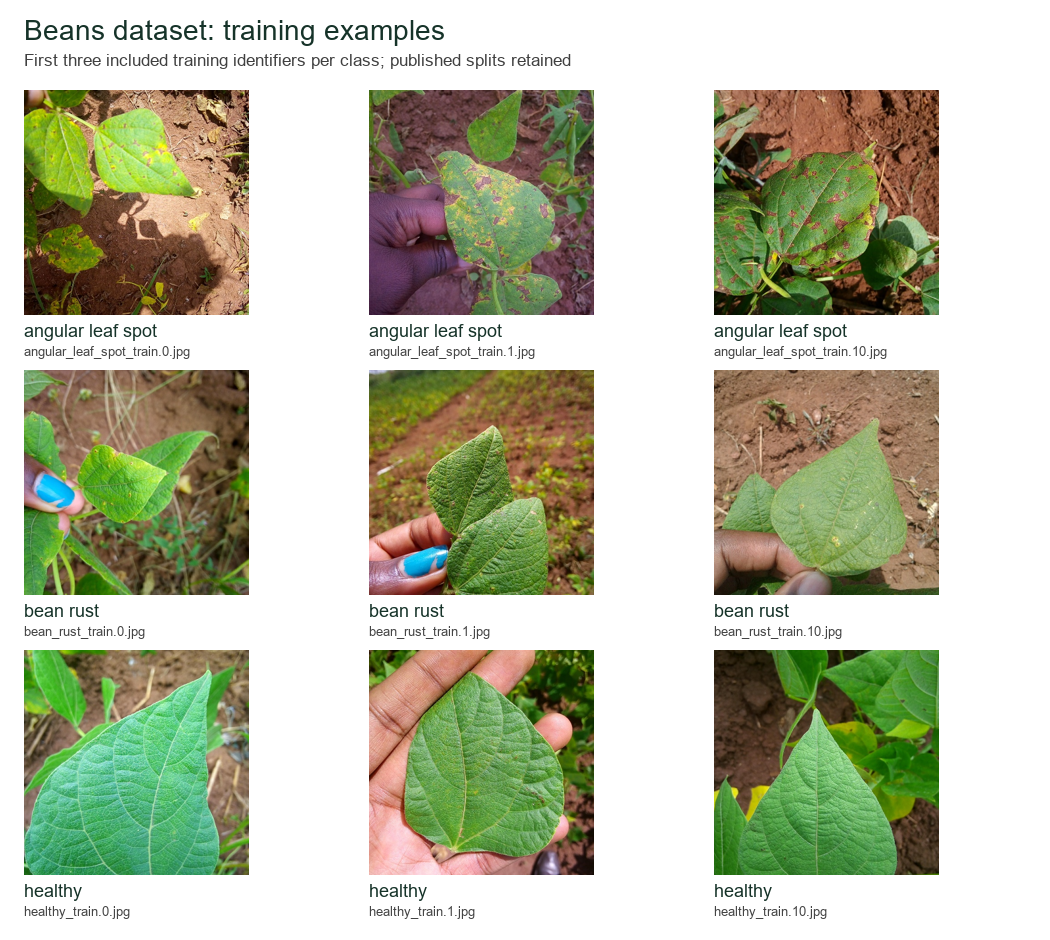

In [4]:
if PLAN_PATH.exists() or (STUDY / "execution_identity.json").exists():
    existing_plan = read_json(PLAN_PATH)
    assert sha256(MANIFEST) == existing_plan["dataset"]["manifest_sha256"]
    print("Reusing the existing immutable manifest:", MANIFEST)
else:
    AUDIT.mkdir(parents=True, exist_ok=True)
    for name in ["review_decisions.csv", "visual_review_record.json"]:
        source = PROJECT_ROOT / "results/data_audit" / name
        if source.is_file():
            shutil.copy2(source, AUDIT / name)
    run("prepare_data.py", "--data-root", DATA_ROOT, "--output-dir", AUDIT,
        "--review-decisions", AUDIT / "review_decisions.csv")
audit = read_json(AUDIT / "audit_summary.json")
assert audit["dataset_revision"] == "27aa014ce09b193e1a6f58112d4a66e0eddb69c5"
assert audit["included_counts"] == {"train": 1034, "validation": 133, "test": 128}
assert not audit["corrupt_images"]
unresolved = {key: count for key, count in audit["visual_review_status"].items()
              if key not in {"distinct", "confirmed_duplicate"} and count}
if unresolved:
    raise RuntimeError(f"Inspect unresolved duplicate candidates before proceeding: {unresolved}")
print(json.dumps({key: audit[key] for key in ["included_counts", "corrupt_images",
                  "near_duplicate_candidate_pairs", "visual_review_status"]}, indent=2))
display(Image(filename=str(AUDIT / "dataset_examples.png"), width=850))


## 4. Record the reproduction plan before the pilot and full training

Absolute paths in the regenerated manifest change its byte hash. Copy the original
plan into this reproduction, replace that manifest path/hash, record the new creation
time and the original plan's checksum, and keep every experimental setting unchanged.
The original plan and original results remain intact. The historical test-exposure
limitation is retained; a reproduction does not undo previous knowledge of the test set.
Record the descriptive timing policy before execution as well, linking the original
timing amendment. Its 809-second observation belongs to the original run; it is not
asserted to have occurred in your reproduction.


In [5]:
original_hash = sha256(ORIGINAL_PLAN)
original = read_json(ORIGINAL_PLAN)
original_timing_hash = sha256(ORIGINAL_TIMING)
original_timing = read_json(ORIGINAL_TIMING)
if TIMING_PATH.exists():
    timing_policy = read_json(TIMING_PATH)
    assert timing_policy["original_amendment_sha256"] == original_timing_hash
    assert timing_policy["before_new_test_evaluation"] is True
    assert timing_policy["raw_times_preserved"] is True
else:
    if (STUDY / "execution_identity.json").exists():
        raise RuntimeError("Execution began without the timing policy; do not retrospectively claim a pre-execution record.")
    observed_test_files = [path for pattern in ["metrics_test*.json", "predictions_test*.csv"]
                           for path in RUN_ROOT.rglob(pattern)]
    assert not observed_test_files, "Cannot record a pre-evaluation policy after test outputs exist."
    timing_policy = {key: original_timing[key] for key in [
        "training_changes", "checkpoint_selection_changes", "test_evaluation_changes",
        "raw_times_preserved", "existing_metrics_retained", "additional_descriptive_statistics",
        "quantile_method", "cost_figure_metric", "exclusions_or_corrections", "interpretation"]}
    timing_policy.update({
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "status": "Timing summary policy carried forward before this reproduction's execution",
        "before_new_test_evaluation": True,
        "original_dinov2_test_results_previously_known": True,
        "observed_new_test_artifact_count": 0,
        "original_amendment": "results/model_comparison/timing_analysis_amendment.json",
        "original_amendment_sha256": original_timing_hash,
        "original_amendment_created_utc": original_timing["created_utc"],
        "motivation": "Apply the original descriptive timing policy to all reproduction epochs; the original unusually long epoch is historical and is not asserted for this runtime.",
    })
    with TIMING_PATH.open("x", encoding="utf-8") as stream:
        json.dump(timing_policy, stream, indent=2)
        stream.write("\n")
if PLAN_PATH.exists():
    plan = read_json(PLAN_PATH)
    assert plan["reproduction"]["original_plan_sha256"] == original_hash
    assert plan["dataset"]["manifest_sha256"] == sha256(MANIFEST)
    assert plan["reproduction"]["run_id"] == RUN_ID
    print("Reusing the existing plan without changing it.")
else:
    if (STUDY / "execution_identity.json").exists():
        raise RuntimeError("Execution began but its plan is missing; do not reconstruct it retrospectively.")
    plan = copy.deepcopy(original)
    plan["created_utc"] = datetime.now(timezone.utc).isoformat()
    plan["study_status"] = "Reproduction of the fixed exploratory follow-up; original test exposure remains disclosed"
    plan["dataset"]["manifest"] = str(MANIFEST.resolve())
    plan["dataset"]["manifest_sha256"] = sha256(MANIFEST)
    plan["reproduction"] = {
        "run_id": RUN_ID,
        "original_plan": "results/model_comparison/study_plan.json",
        "original_plan_sha256": original_hash,
        "original_plan_created_utc": original["created_utc"],
        "experimental_settings_changed": False,
        "regenerated_manifest_has_runtime_specific_absolute_paths": True,
        "prior_test_exposure_retained": True,
        "timing_policy_sha256": sha256(TIMING_PATH),
    }
    with PLAN_PATH.open("x", encoding="utf-8") as stream:
        json.dump(plan, stream, indent=2)
        stream.write("\n")
assert sha256(ORIGINAL_PLAN) == original_hash
assert plan["settings"] == original["settings"] and plan["models"] == original["models"]
assert plan["reproduction"]["timing_policy_sha256"] == sha256(TIMING_PATH)
assert sha256(ORIGINAL_TIMING) == original_timing_hash
print(json.dumps({"models": plan["models"], "settings": plan["settings"]}, indent=2))
print("Recorded reproduction plan:", PLAN_PATH, "| SHA256:", sha256(PLAN_PATH))

def phase(name):
    run("run_model_comparison.py", "--manifest", MANIFEST, "--data-root", IMAGE_ROOT,
        "--run-root", RUN_ROOT, "--out", STUDY, "--study-plan", PLAN_PATH,
        "--device", DEVICE, "--phase", name, "--resume")


{
  "models": {
    "dinov2": {
      "model_id": "facebook/dinov2-small",
      "revision": "ed25f3a31f01632728cabb09d1542f84ab7b0056",
      "readout": "Final normalized CLS token,384dim",
      "resize": "Full224 bicubic as original study",
      "normalization_mean": [
        0.485,
        0.456,
        0.406
      ],
      "normalization_std": [
        0.229,
        0.224,
        0.225
      ]
    },
    "siglip2": {
      "model_id": "google/siglip2-base-patch16-224",
      "revision": "75de2d55ec2d0b4efc50b3e9ad70dba96a7b2fa2",
      "readout": "Pretrained attention-pooled image representation,768dim; vision tower only",
      "resize": "Official full224 bilinear",
      "normalization_mean": [
        0.5,
        0.5,
        0.5
      ],
      "normalization_std": [
        0.5,
        0.5,
        0.5
      ]
    }
  },
  "settings": {
    "seeds": [
      17,
      42,
      2026
    ],
    "arms": [
      "frozen",
      "partial"
    ],
    "runs": 12,
    "batch_s

## 5. Run full-epoch pilots for both models and both arms

Each pilot checks gradients, frozen parameters and checkpoint round trips, and
benchmarks one complete training epoch. Full experiments restart from the pinned
pretrained weights. The scripts download official checkpoints automatically and use
their pinned revisions; no remote executable model code is required. No test
prediction is requested by this phase. Check actual memory and timing before proceeding.


In [6]:
phase("pilot")
pilots = []
for model in plan["models"]:
    records = read_json(STUDY / model / "pilot_report.json")
    assert len(records) == 2 and all(item["status"] == "passed" for item in records)
    for item in records:
        pilots.append({"model": model, "arm": item["arm"],
                       "one_training_epoch_seconds": item["training"]["seconds"],
                       "peak_cuda_allocated_bytes": item["peak_cuda_allocated_bytes"]})
display(pd.DataFrame(pilots))
training_minutes = sum(row["one_training_epoch_seconds"] for row in pilots) * plan["settings"]["epochs"] * len(plan["settings"]["seeds"]) / 60
print("Full-epoch-budget training-only estimate in minutes:", round(training_minutes, 1))
print("This excludes validation, downloads, loading, checkpoint I/O and analysis.")


Running run_model_comparison.py


{"event": "command", "script": "followup_experiment.py", "arguments": ["pilot", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--batch-size", "8", "--device", "cuda", "--epochs", "10", "--patience", "3", "--head-lr", "0.001", "--backbone-lr", "1e-05", "--weight-decay", "0.01", "--model-id", "facebook/dinov2-small", "--revision", "ed25f3a31f01632728cabb09d1542f84ab7b0056", "--output-dir", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2", "--benchmark-epoch"], "utc": "2026-10-24T13:50:14.978435+00:00"}


D:\CodexWork\beans-vit-project\venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\CodexWork\beans-vit-project\notebook_validation_20261024\work\huggingface\hub\models--facebook--dinov2-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.


To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development


  warnings.warn(message)


...

  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


{"event": "pilot", "arm": "partial", "status": "passed", "seconds": 16.959862899995642, "n": 1034, "peak_cuda_allocated_bytes": 722832384}


REQUESTED_PHASE_COMPLETE


,model,arm,one_training_epoch_seconds,peak_cuda_allocated_bytes
0,dinov2,frozen,22.283165,191750144
1,dinov2,partial,14.249565,288328704
2,siglip2,frozen,13.612079,482031616
3,siglip2,partial,16.959863,722832384


Full-epoch-budget training-only estimate in minutes: 33.6
This excludes validation, downloads, loading, checkpoint I/O and analysis.


## 6. Train all 12 runs with validation-only checkpoint selection

Images receive the model's recorded full-image resizing and normalization. Augmentation
randomness and image order are matched across backbones by seed, epoch and image ID.
Classifier initialization is paired within a backbone; embedding dimensions differ
across backbones. AdamW settings, batch size, epoch limit and stopping rule are fixed.
Select by highest validation macro-F1, then lower loss, then earlier epoch. Only a strict
F1 improvement resets patience. The implementation permits platform-specific
nondeterministic CUDA operations with a warning; bitwise identical reruns are not promised.

Completed matching runs may be reused with `--resume`; incomplete runs are never
overwritten automatically. Keep temporary runtime checkpoints if resumption is needed.


In [7]:
phase("train")
summaries = []
for model in plan["models"]:
    for arm in plan["settings"]["arms"]:
        for seed in plan["settings"]["seeds"]:
            folder = RUN_ROOT / model / "runs" / arm / f"seed_{seed}"
            summary = read_json(folder / "summary.json")
            assert (folder / "best.pt").is_file()
            summaries.append({"model": model, **{key: summary[key] for key in
                ["arm", "seed", "best_epoch", "epochs_completed", "best_validation_macro_f1", "training_seconds"]}})
assert len(summaries) == 12
display(pd.DataFrame(summaries))
print("Training complete. The table shows validation selection; this phase did not request test inference.")


Running run_model_comparison.py


{"event": "command", "script": "followup_experiment.py", "arguments": ["train", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--batch-size", "8", "--device", "cuda", "--epochs", "10", "--patience", "3", "--head-lr", "0.001", "--backbone-lr", "1e-05", "--weight-decay", "0.01", "--model-id", "facebook/dinov2-small", "--revision", "ed25f3a31f01632728cabb09d1542f84ab7b0056", "--output-dir", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2\\runs", "--seeds", "17", "--arm", "frozen"], "utc": "2026-10-24T13:52:48.232440+00:00"}


{"event": "epoch", "arm": "frozen", "seed": 17, "epoch": 1, "train_loss": 0.5228290982126498, "validation_loss": 0.3925923153870088, "validation_macro_f1": 0.831469486671073, "train_seconds": 12.935379000002285, "best_epoch": 1}


{"event": "epoch", "arm": "frozen", "seed": 17, "epoch": 2, "train_loss": 0.280650679562493, "validation_loss": 0.2850679652135175, "validation_macro_f1": 0.9107565198498045, "train_seconds": 12.8926941000027, "best_epoch": 2}


{"event": "epoch", "arm": "frozen", "seed": 17, "epoch": 3, "train_loss": 0.23374579492343925, "validation_loss": 0.21747819821637376, "validation_macro_f1": 0.9101282691987341, "train_seconds": 12.669919100000698, "best_epoch": 2}


...

{"event": "epoch", "arm": "partial", "seed": 2026, "epoch": 10, "train_loss": 0.034607540707984795, "validation_loss": 0.13107653130266003, "validation_macro_f1": 0.9699425869638635, "train_seconds": 16.08223800000269, "best_epoch": 8}


{"event": "run_complete", "arm": "partial", "seed": 2026, "epochs_completed": 10, "best_epoch": 8, "best_validation_macro_f1": 0.9702194793300055, "best_val_macro_f1": 0.9702194793300055, "best_validation_loss": 0.11894368946104121, "wall_seconds": 191.8391338999936, "training_seconds": 162.3074755000198, "validation_seconds": 14.495988599999691, "peak_cuda_allocated_bytes": 722230272, "peak_cuda_reserved_bytes": 815792128, "trainable_params": 14179587, "total_params": 92886531, "total_parameters": 92886531, "trainable_parameters": 14179587, "unfrozen_modules": ["vision_model.encoder.layers.10", "vision_model.encoder.layers.11", "vision_model.post_layernorm"], "test_evaluated": false}


REQUESTED_PHASE_COMPLETE


,model,arm,seed,best_epoch,epochs_completed,best_validation_macro_f1,training_seconds
0,dinov2,frozen,17,9,10,0.955220,126.478962
1,dinov2,frozen,42,2,5,0.910128,59.026564
2,dinov2,frozen,2026,10,10,0.954992,109.713778
3,dinov2,partial,17,3,5,0.970219,63.142423
4,dinov2,partial,42,4,7,0.985002,4321.956196
5,dinov2,partial,2026,6,9,0.992509,108.622255
6,siglip2,frozen,17,10,10,0.955255,127.963901
7,siglip2,frozen,42,5,8,0.954914,105.096224
8,siglip2,frozen,2026,9,10,0.962471,6735.820619
9,siglip2,partial,17,6,9,0.985002,145.829898


Training complete. The table shows validation selection; this phase did not request test inference.


## 7. Lock the selected checkpoints and evaluate the existing test split

The driver requires every planned run, verifies configurations and hashes, and creates
both model locks before new test inference. The validator checks membership and hashes
before each evaluation. The lock records that this is an exploratory reuse of a test
set evaluated in the earlier study, not a fresh confirmatory holdout.

Evaluate clean test images for all 12 selected checkpoints. Seed 17 additionally uses
the already-fixed blur radius 1 and brightness ×0.7 conditions. These are paired
synthetic sensitivity checks, not new independent field observations. Do not use their
scores for more tuning or replace checkpoints after seeing test results.


In [8]:
phase("evaluate")
print(json.dumps(read_json(STUDY / "evaluation_completion.json"), indent=2))
for model in plan["models"]:
    lock = read_json(STUDY / model / "protocol.lock.json")
    assert lock["original_dinov2_test_results_known_before_followup"] is True
    assert lock["new_followup_test_predictions_evaluated_before_lock"] is False
    print(model, "lock:", sha256(STUDY / model / "protocol.lock.json"))


Running run_model_comparison.py


{"event": "command", "script": "followup_experiment.py", "arguments": ["evaluate", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--batch-size", "8", "--device", "cuda", "--epochs", "10", "--patience", "3", "--head-lr", "0.001", "--backbone-lr", "1e-05", "--weight-decay", "0.01", "--checkpoint", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2\\runs\\frozen\\seed_17\\best.pt", "--output-dir", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2\\runs\\frozen\\seed_17", "--split", "test", "--confirm-test-locked", "--protocol-lock", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\compariso

{"event": "evaluation", "output_stem": "test", "n": 128, "accuracy": 0.8984375, "macro_f1": 0.8993187395066512, "confusion_matrix": [[39, 4, 0], [3, 39, 1], [2, 3, 37]], "per_class": [{"label": 0, "name": "angular_leaf_spot", "precision": 0.8863636363636364, "recall": 0.9069767441860465, "f1": 0.896551724137931, "support": 43}, {"label": 1, "name": "bean_rust", "precision": 0.8478260869565217, "recall": 0.9069767441860465, "f1": 0.8764044943820224, "support": 43}, {"label": 2, "name": "healthy", "precision": 0.9736842105263158, "recall": 0.8809523809523809, "f1": 0.925, "support": 42}], "loss": 0.17062328476458788, "seconds": 2.4555974999966566, "arm": "frozen", "seed": 17, "split": "test", "corruption": "clean", "checkpoint_epoch": 9, "checkpoint_sha256": "f1179c23d12be7d181e1432493ca04061fe37bc031636e974840ffe080d7dd59", "manifest_sha256": "97a098b142d5a72aa9986305b10543b8e41b8b67369ba76e4c43936e322724d6", "protocol_lock_sha256": "8e037776539cd276ed5d54ec9d9012ebfada30a8989c5b2293313

{"event": "command", "script": "followup_experiment.py", "arguments": ["evaluate", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--batch-size", "8", "--device", "cuda", "--epochs", "10", "--patience", "3", "--head-lr", "0.001", "--backbone-lr", "1e-05", "--weight-decay", "0.01", "--checkpoint", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2\\runs\\frozen\\seed_17\\best.pt", "--output-dir", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\dinov2\\runs\\frozen\\seed_17", "--split", "test", "--confirm-test-locked", "--protocol-lock", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\compariso

{"event": "evaluation", "output_stem": "test_blur", "n": 128, "accuracy": 0.921875, "macro_f1": 0.9224534005852209, "confusion_matrix": [[40, 3, 0], [2, 41, 0], [2, 3, 37]], "per_class": [{"label": 0, "name": "angular_leaf_spot", "precision": 0.9090909090909091, "recall": 0.9302325581395349, "f1": 0.9195402298850575, "support": 43}, {"label": 1, "name": "bean_rust", "precision": 0.8723404255319149, "recall": 0.9534883720930233, "f1": 0.9111111111111112, "support": 43}, {"label": 2, "name": "healthy", "precision": 1.0, "recall": 0.8809523809523809, "f1": 0.9367088607594937, "support": 42}], "loss": 0.202163215726614, "seconds": 1.5943170000027749, "arm": "frozen", "seed": 17, "split": "test", "corruption": "blur", "checkpoint_epoch": 9, "checkpoint_sha256": "f1179c23d12be7d181e1432493ca04061fe37bc031636e974840ffe080d7dd59", "manifest_sha256": "97a098b142d5a72aa9986305b10543b8e41b8b67369ba76e4c43936e322724d6", "protocol_lock_sha256": "8e037776539cd276ed5d54ec9d9012ebfada30a8989c5b2293313

...

{"event": "evaluation", "output_stem": "test", "n": 128, "accuracy": 0.9609375, "macro_f1": 0.9611930869545597, "confusion_matrix": [[42, 1, 0], [4, 39, 0], [0, 0, 42]], "per_class": [{"label": 0, "name": "angular_leaf_spot", "precision": 0.9130434782608695, "recall": 0.9767441860465116, "f1": 0.9438202247191011, "support": 43}, {"label": 1, "name": "bean_rust", "precision": 0.975, "recall": 0.9069767441860465, "f1": 0.9397590361445783, "support": 43}, {"label": 2, "name": "healthy", "precision": 1.0, "recall": 1.0, "f1": 1.0, "support": 42}], "loss": 0.1215013638138771, "seconds": 1.6681643999982043, "arm": "frozen", "seed": 2026, "split": "test", "corruption": "clean", "checkpoint_epoch": 9, "checkpoint_sha256": "652945375df7622dbc3d24427cf9b13ecf4627e3b786802f6f37b99f6aa830cd", "manifest_sha256": "97a098b142d5a72aa9986305b10543b8e41b8b67369ba76e4c43936e322724d6", "protocol_lock_sha256": "835e41c16931b5197546cdd8e6611a4cabda0a4225c91b547005ea5d1555b008"}


{"event": "command", "script": "followup_experiment.py", "arguments": ["evaluate", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--batch-size", "8", "--device", "cuda", "--epochs", "10", "--patience", "3", "--head-lr", "0.001", "--backbone-lr", "1e-05", "--weight-decay", "0.01", "--checkpoint", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\siglip2\\runs\\partial\\seed_2026\\best.pt", "--output-dir", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\comparison_runs\\comparison_20261024T134944Z\\siglip2\\runs\\partial\\seed_2026", "--split", "test", "--confirm-test-locked", "--protocol-lock", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\c

{"event": "evaluation", "output_stem": "test", "n": 128, "accuracy": 0.9609375, "macro_f1": 0.9611820880113564, "confusion_matrix": [[40, 3, 0], [0, 43, 0], [1, 1, 40]], "per_class": [{"label": 0, "name": "angular_leaf_spot", "precision": 0.975609756097561, "recall": 0.9302325581395349, "f1": 0.9523809523809524, "support": 43}, {"label": 1, "name": "bean_rust", "precision": 0.9148936170212766, "recall": 1.0, "f1": 0.9555555555555556, "support": 43}, {"label": 2, "name": "healthy", "precision": 1.0, "recall": 0.9523809523809523, "f1": 0.975609756097561, "support": 42}], "loss": 0.2211315669119358, "seconds": 1.6314253999953507, "arm": "partial", "seed": 2026, "split": "test", "corruption": "clean", "checkpoint_epoch": 8, "checkpoint_sha256": "e056c92e7bb879e4b5d0b4dfbab81b67fc05714f39abeb216634508f5351fc6f", "manifest_sha256": "97a098b142d5a72aa9986305b10543b8e41b8b67369ba76e4c43936e322724d6", "protocol_lock_sha256": "835e41c16931b5197546cdd8e6611a4cabda0a4225c91b547005ea5d1555b008"}


REQUESTED_PHASE_COMPLETE


{
  "completed_utc": "2026-10-24T17:26:10.892932+00:00",
  "test_runs": 12,
  "additional_synthetic_conditions": 8,
  "all_training_completed_first": true
}
dinov2 lock: 8e037776539cd276ed5d54ec9d9012ebfada30a8989c5b2293313f49049cf48b
siglip2 lock: 835e41c16931b5197546cdd8e6611a4cabda0a4225c91b547005ea5d1555b008


## 8. Analyse metrics, uncertainty, cost and overfitting

The analysis recomputes metrics from saved predictions and produces all-seed summaries,
class metrics, confusion matrices, real sample errors and synthetic sensitivity figures.
The primary model difference is partial SigLIP2 minus partial DINOv2. Seed 17 uses
2,000 paired class-stratified bootstrap resamples with seed 20261023. This descriptive
interval is conditional on the reused test sample and reference pair; it is not an
interval for the three-seed mean or an independent superiority confirmation.

**Timing analysis amendment:** an unusually long epoch was observed during the original
follow-up's training, before its test evaluation. The amended analysis adds median,
quartiles and range of observed epoch times while retaining every raw epoch duration
and total. These describe the recorded hardware session; they are not a controlled
throughput benchmark or proof of the slowdown's cause. Your reproduction may have
different timing variation. Compare total observed training cost as well as medians.
The completed original follow-up also contains a 184.36-second SigLIP2 partial epoch,
as well as the 809.10-second frozen epoch that motivated the amendment. Both remain
in all timing summaries; neither has an established cause.

Clean training and validation inference scores each unchanged selected checkpoint with
no augmentation or parameter updates. Saved test metrics provide context. All-seed
learning curves reveal late deterioration; a small clean train-validation gap cannot
prove absence of overfitting, leakage or distribution shift. Online augmented training
loss and fixed-checkpoint clean loss are different evaluations.


Running run_model_comparison.py


{"event": "command", "script": "analyse_results.py", "arguments": ["--runs", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\dinov2\\runs", "--manifest", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\data_audit\\manifest.csv", "--data-root", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\work\\data\\beans\\images", "--out", "D:\\CodexWork\\beans-vit-project\\notebook_validation_20261024\\results\\reproduction\\comparison_20261024T134944Z\\dinov2"], "utc": "2026-10-24T17:26:11.070139+00:00"}


{


  "comparison": [


    {


...

REQUESTED_PHASE_COMPLETE


,model,arm,runs,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,training_seconds_mean,training_seconds_sd,mean_training_epoch_seconds_mean,...,pooled_training_seconds_per_epoch,trainable_params,total_params,peak_cuda_allocated_bytes_max,pooled_epoch_median_seconds,pooled_epoch_q1_seconds,pooled_epoch_q3_seconds,pooled_epoch_iqr_seconds,pooled_epoch_min_seconds,pooled_epoch_max_seconds
0,dinov2,frozen,3,0.906250,0.020670,0.907129,0.020536,98.406435,35.119062,11.808196,...,11.808772,1155,22057731,191755264,11.683462,11.030517,12.669919,1.639402,10.749654,13.349281
1,dinov2,partial,3,0.976562,0.007812,0.976701,0.007806,1497.906958,2445.804096,214.039979,...,213.986708,3552387,22057731,287726592,12.141522,11.965738,12.316264,0.350526,11.582004,4250.521720
2,siglip2,frozen,3,0.968750,0.013532,0.968972,0.013437,2322.960248,3821.666289,233.171827,...,248.888598,2307,92886531,482041344,12.867625,12.732201,13.326867,0.594666,12.398314,6617.507268
3,siglip2,partial,3,0.968750,0.007812,0.968989,0.007767,140.471929,24.949811,16.205567,...,16.208300,14179587,92886531,722230272,16.187877,16.072679,16.253896,0.181217,15.921328,16.896092


,model,arm,pooled_epochs,pooled_epoch_median_seconds,pooled_epoch_q1_seconds,pooled_epoch_q3_seconds,pooled_epoch_iqr_seconds,pooled_epoch_min_seconds,pooled_epoch_max_seconds,pooled_training_seconds,pooled_training_seconds_per_epoch,training_seconds_mean
0,dinov2,frozen,25,11.683462,11.030517,12.669919,1.639402,10.749654,13.349281,295.219304,11.808772,98.406435
1,dinov2,partial,21,12.141522,11.965738,12.316264,0.350526,11.582004,4250.521720,4493.720874,213.986708,1497.906958
2,siglip2,frozen,28,12.867625,12.732201,13.326867,0.594666,12.398314,6617.507268,6968.880743,248.888598,2322.960248
3,siglip2,partial,26,16.187877,16.072679,16.253896,0.181217,15.921328,16.896092,421.415788,16.208300,140.471929


,arm,seed,dinov2_macro_f1,siglip2_macro_f1,siglip2_minus_dinov2_macro_f1,dinov2_accuracy,siglip2_accuracy,siglip2_minus_dinov2_accuracy
0,frozen,17,0.899319,0.984488,0.085169,0.898438,0.984375,0.085938
1,frozen,42,0.891644,0.961235,0.069591,0.890625,0.960938,0.070312
2,frozen,2026,0.930424,0.961193,0.030769,0.929688,0.960938,0.031250
3,partial,17,0.984487,0.976716,-0.007771,0.984375,0.976562,-0.007812
4,partial,42,0.976741,0.969068,-0.007673,0.976562,0.968750,-0.007812
5,partial,2026,0.968875,0.961182,-0.007693,0.968750,0.960938,-0.007812


{
  "ci95_percentile": [
    -0.0313437134008446,
    0.01570583887657051
  ],
  "resamples": 2000,
  "seed": 20261023,
  "method": "paired class-stratified percentile bootstrap",
  "limitation": "Conditional on observed classes and independent audited images; unknown plant/farm dependence is not corrected.",
  "difference_siglip2_minus_dinov2": -0.007770757367027481,
  "arm": "partial",
  "reference_seed": 17,
  "scope": "Descriptive interval for the seed-17 model pair on the previously evaluated test split; not an interval for the three-seed mean or a fresh confirmatory test."
}
Timing interpretation: Descriptive measured durations, not corrected hardware benchmarks. Different completed epoch counts weight seeds differently in pooled epoch summaries; raw run totals, run means and pooled means remain reported. No cause is assigned to unusually long epochs.


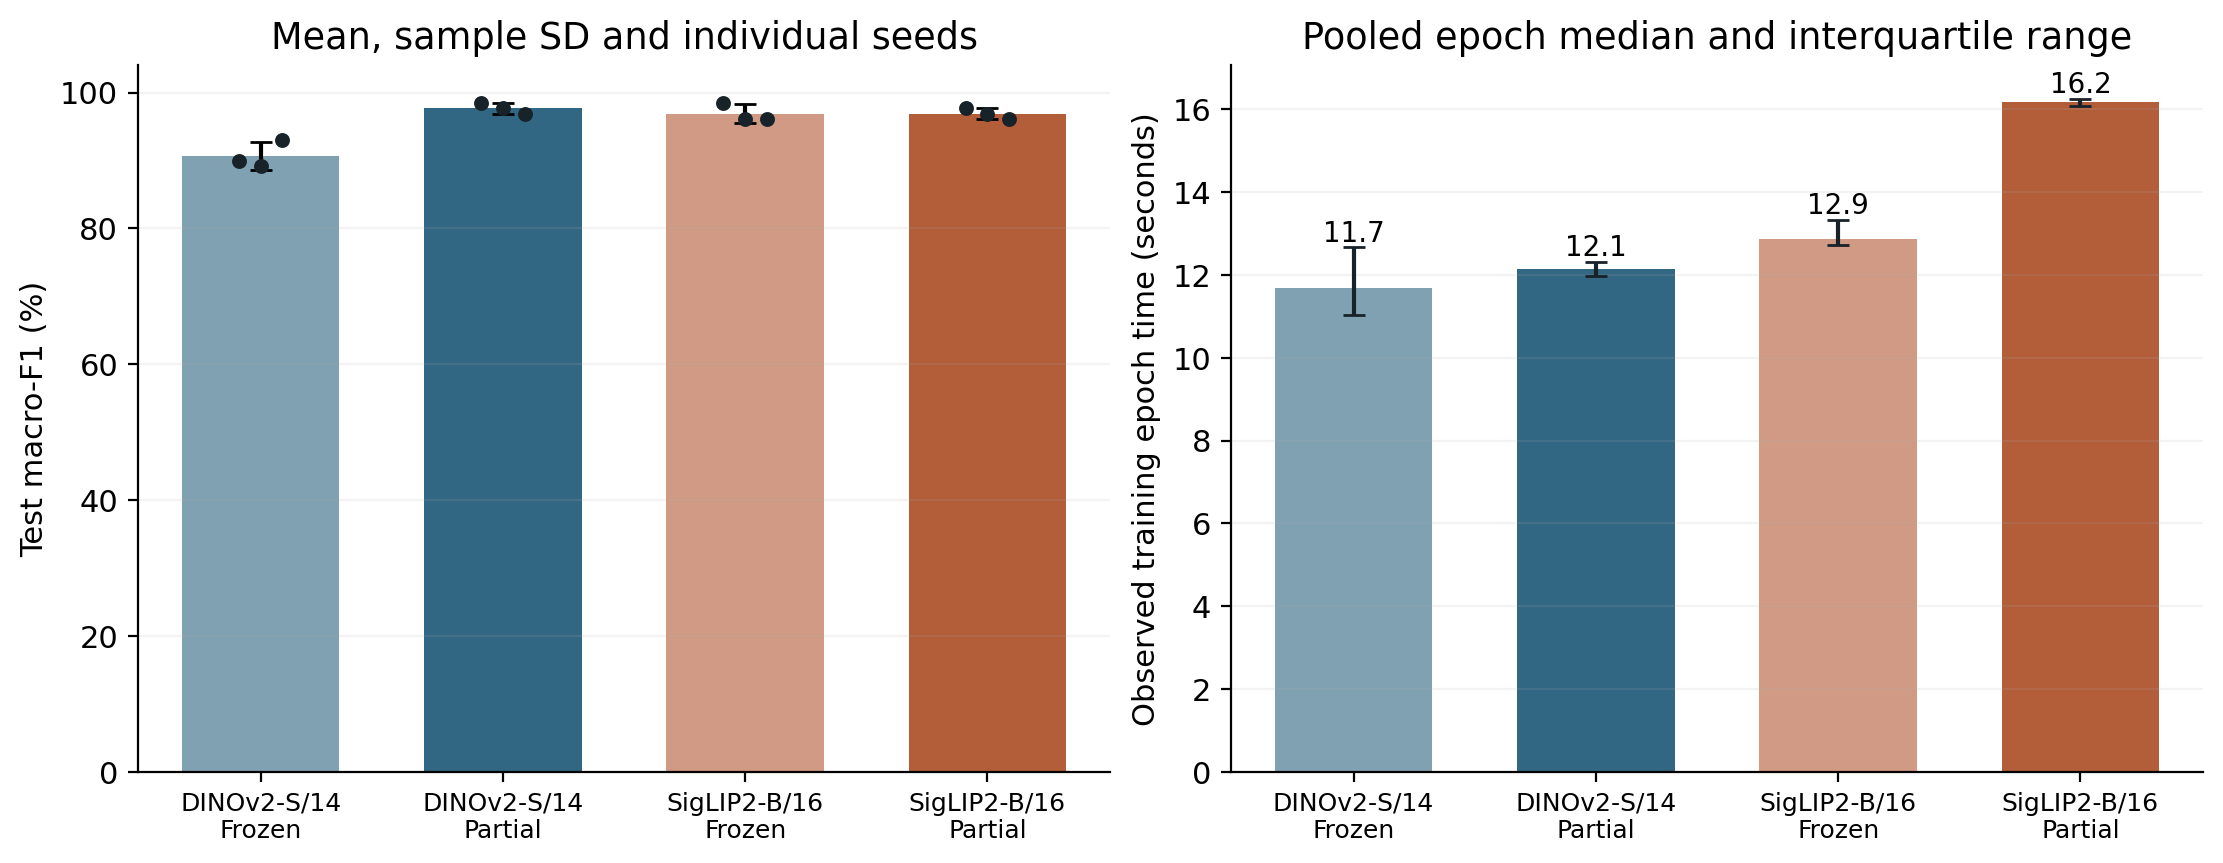

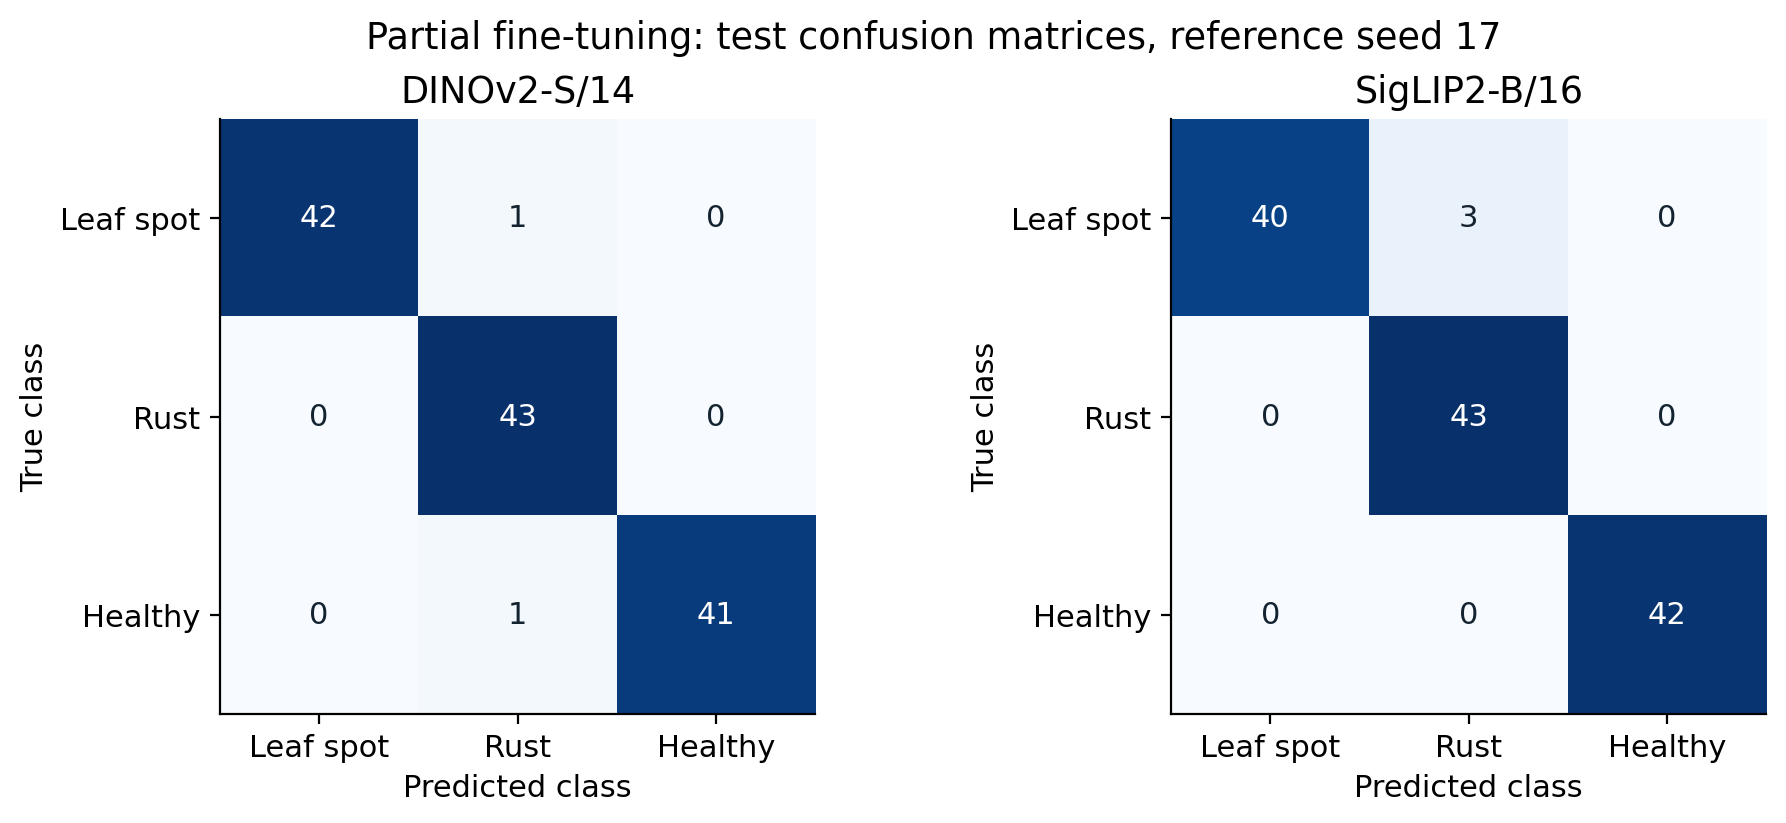

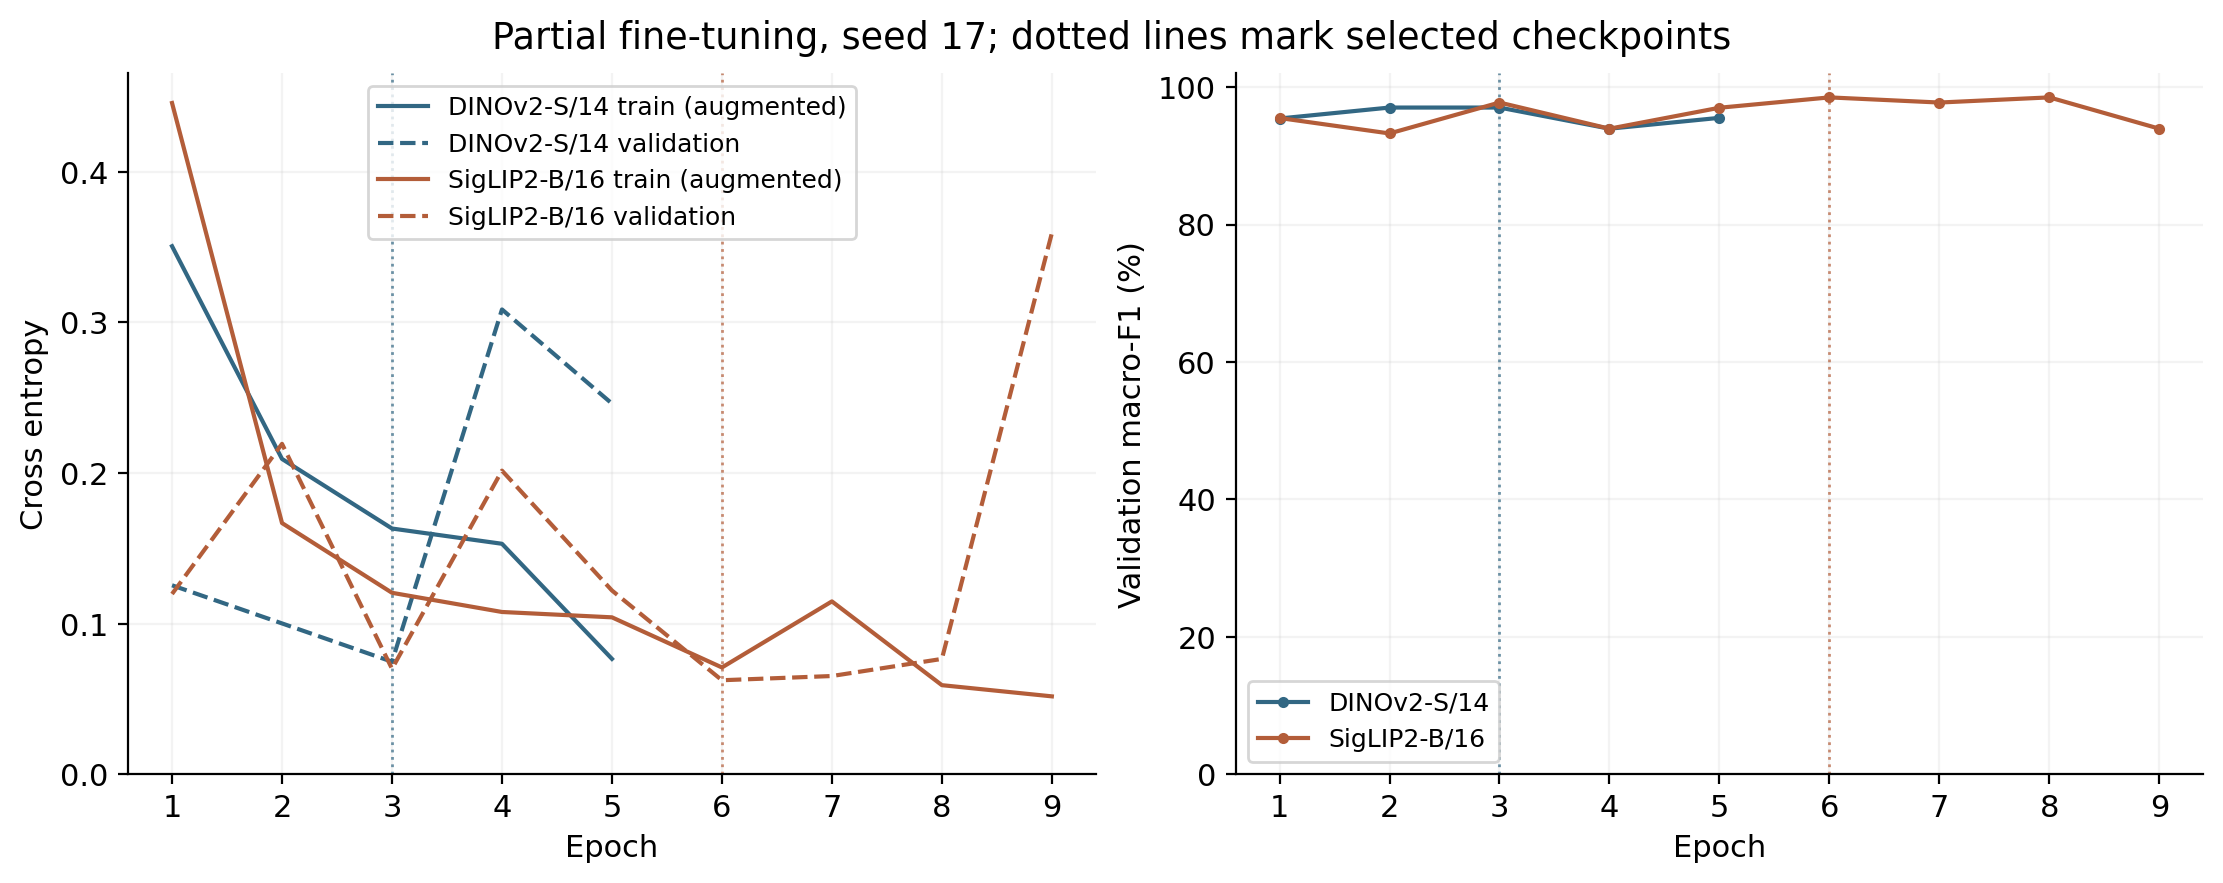

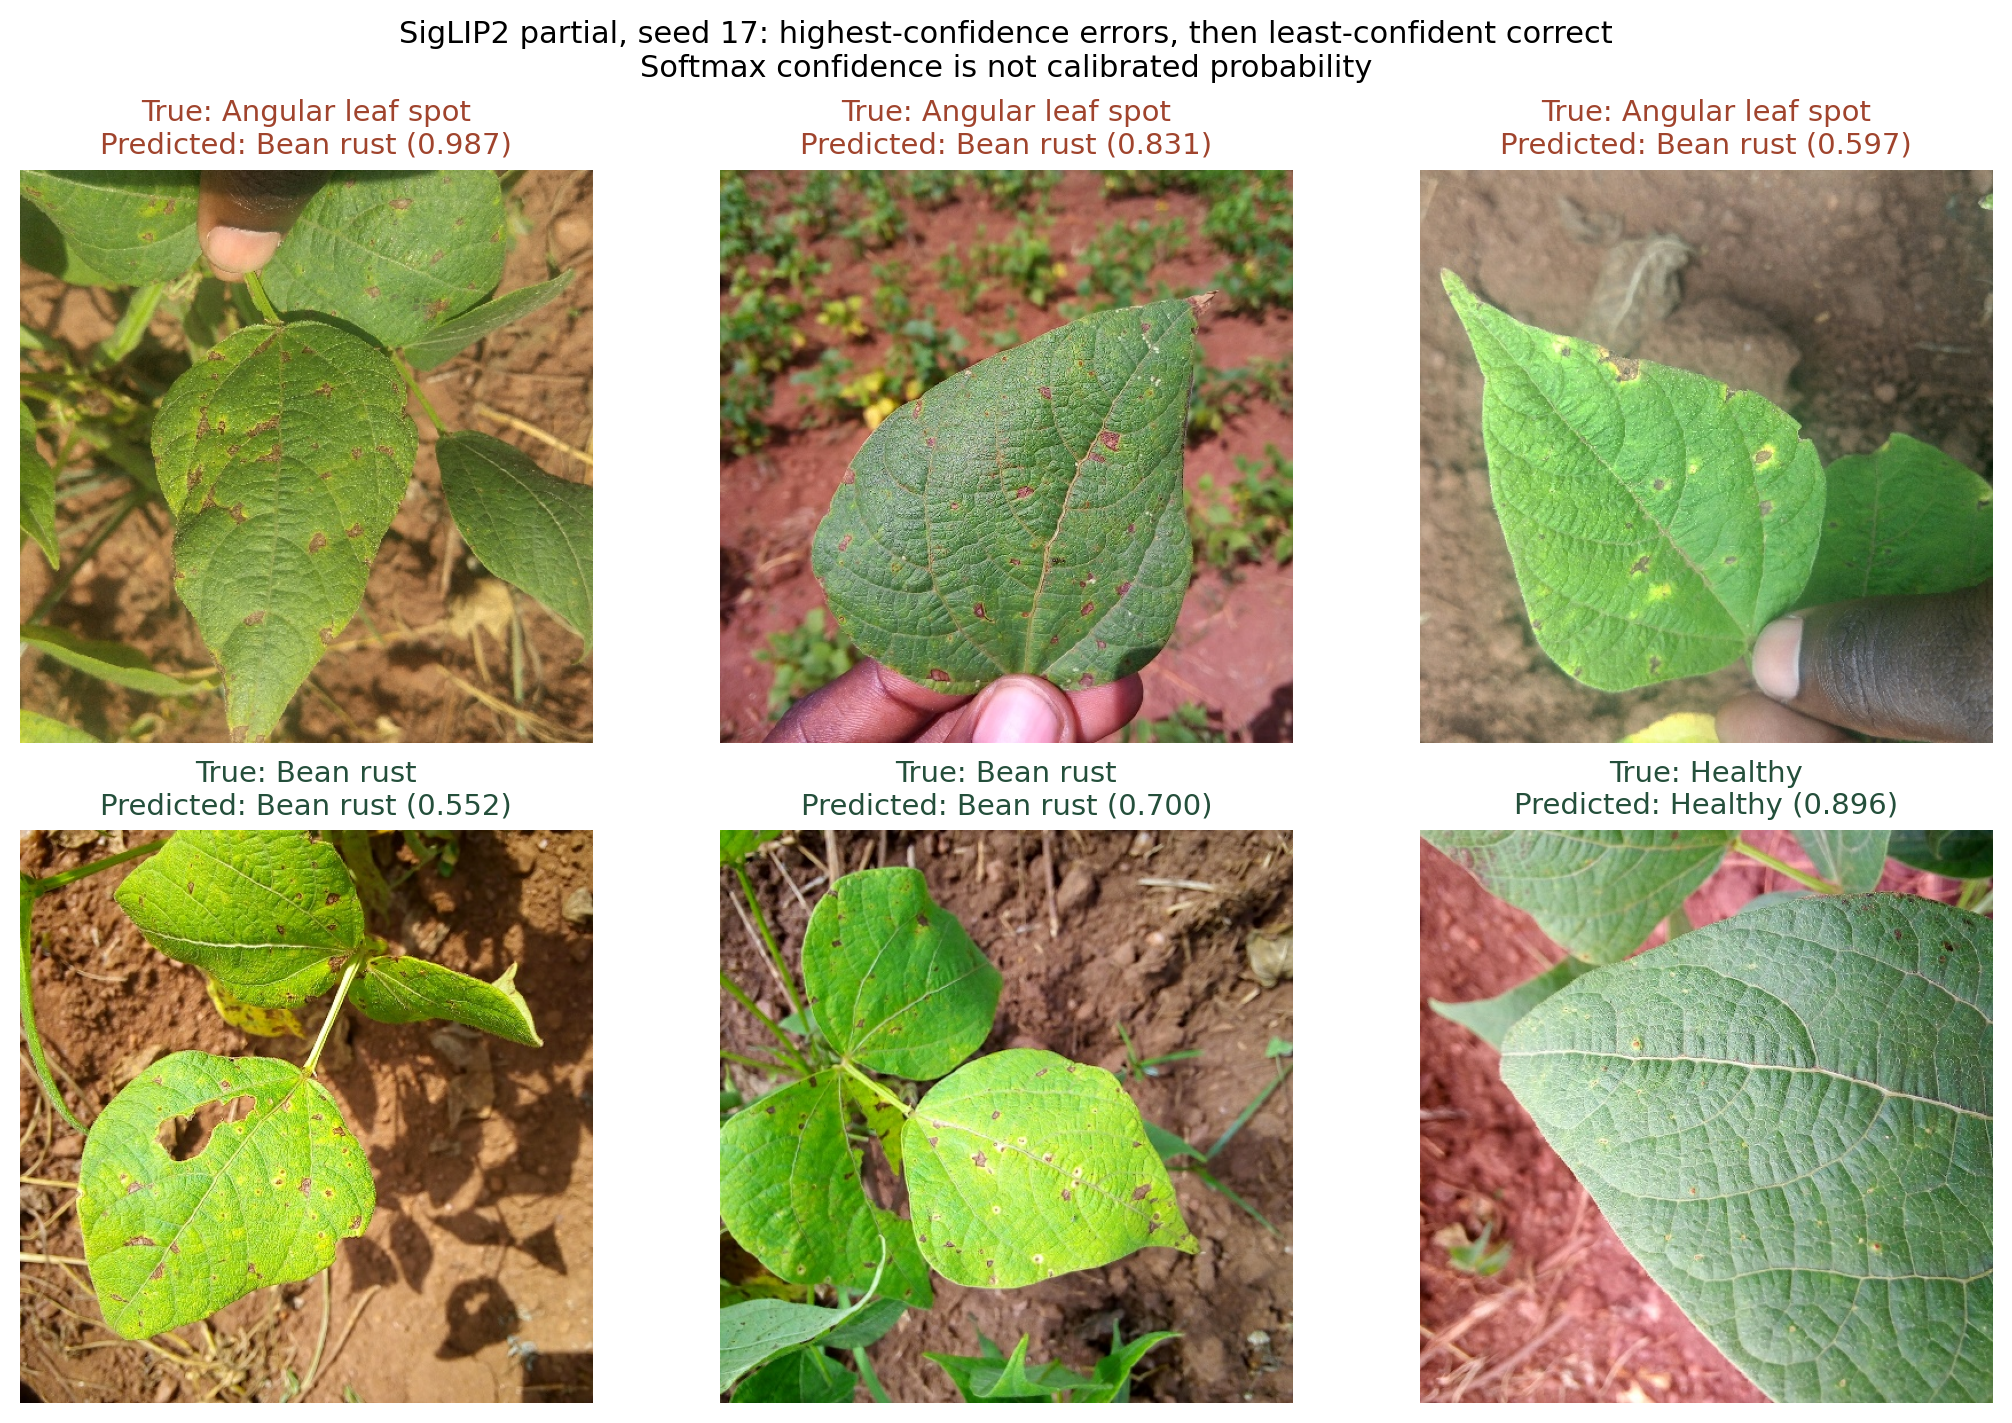

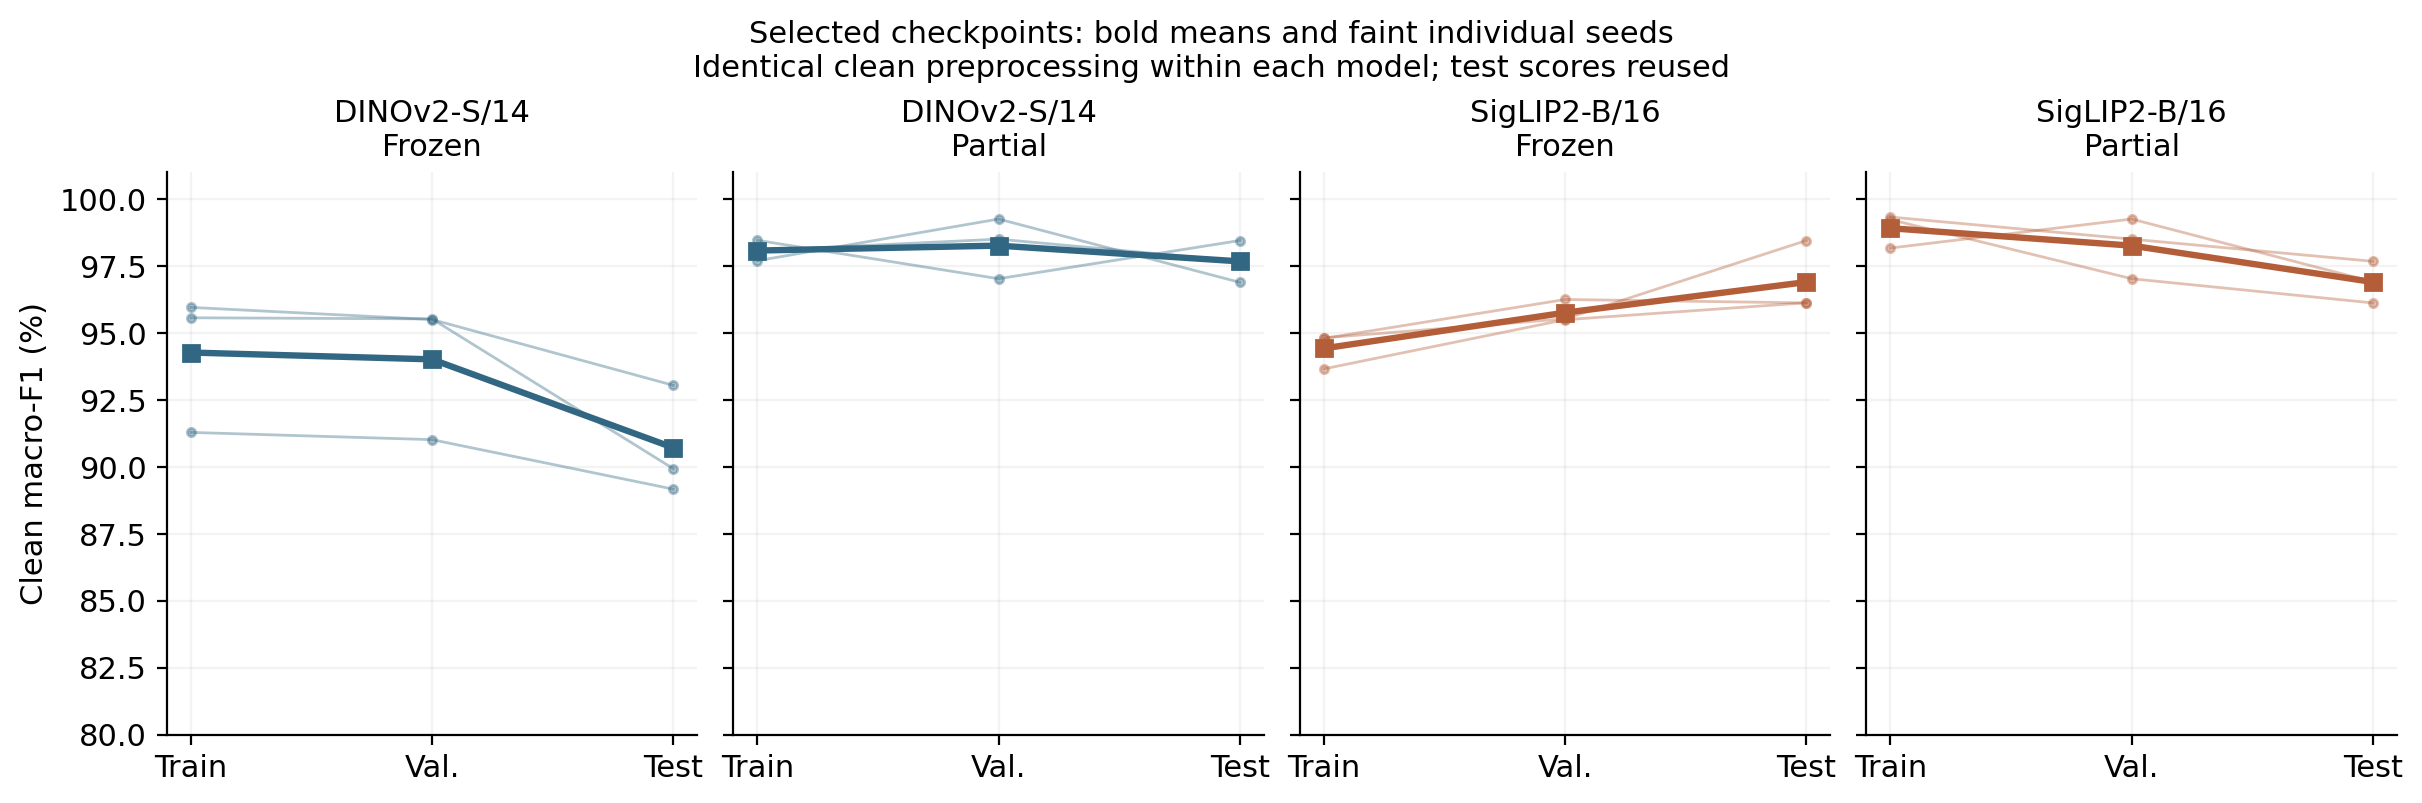

dinov2 selected-checkpoint clean gaps and trajectory diagnostics


,arm,runs,train_macro_f1_mean,validation_macro_f1_mean,test_macro_f1_mean,train_accuracy_mean,validation_accuracy_mean,train_loss_mean,validation_loss_mean,train_minus_validation_f1_pp_mean,train_minus_test_f1_pp_mean
0,frozen,3,0.942662,0.940113,0.907129,0.942618,0.939850,0.157603,0.190108,0.254864,3.553303
1,partial,3,0.980742,0.982577,0.976701,0.980658,0.982456,0.080641,0.053432,-0.183520,0.404077


,arm,seed,selected_epoch,final_epoch,selected_validation_loss,final_validation_loss,final_minus_selected_validation_loss,selected_minus_final_validation_f1_pp,post_selection_epochs,post_selection_epochs_with_higher_validation_loss,final_minus_selected_augmented_training_loss
0,frozen,17,9,10,0.122580,0.151110,0.028530,0.749064,1,1,-0.016528
1,frozen,42,2,5,0.303081,0.225457,-0.077624,1.628126,3,1,-0.111993
2,frozen,2026,10,10,0.144663,0.144663,0.000000,0.000000,0,0,0.000000
3,partial,17,3,5,0.074810,0.246130,0.171320,1.496455,2,2,-0.086512
4,partial,42,4,7,0.058936,0.112721,0.053785,1.508967,3,2,-0.027574
5,partial,2026,6,9,0.026550,0.146925,0.120374,1.502676,3,3,-0.068900


siglip2 selected-checkpoint clean gaps and trajectory diagnostics


,arm,runs,train_macro_f1_mean,validation_macro_f1_mean,test_macro_f1_mean,train_accuracy_mean,validation_accuracy_mean,train_loss_mean,validation_loss_mean,train_minus_validation_f1_pp_mean,train_minus_test_f1_pp_mean
0,frozen,3,0.944216,0.957547,0.968972,0.943907,0.957393,0.167996,0.128554,-1.333024,-2.475560
1,partial,3,0.989078,0.982576,0.968989,0.989039,0.982456,0.040315,0.066580,0.650258,2.008961


,arm,seed,selected_epoch,final_epoch,selected_validation_loss,final_validation_loss,final_minus_selected_validation_loss,selected_minus_final_validation_f1_pp,post_selection_epochs,post_selection_epochs_with_higher_validation_loss,final_minus_selected_augmented_training_loss
0,frozen,17,10,10,0.114987,0.114987,0.000000,0.000000,0,0,0.000000
1,frozen,42,5,8,0.157254,0.165734,0.008480,0.680112,3,2,-0.045127
2,frozen,2026,9,10,0.113423,0.123997,0.010575,1.467335,1,1,-0.004772
3,partial,17,6,9,0.062517,0.359266,0.296749,4.554590,3,3,-0.019179
4,partial,42,4,7,0.018278,0.210090,0.191812,3.772916,3,3,-0.019219
5,partial,2026,8,10,0.118944,0.131077,0.012133,0.027689,2,2,-0.017772


Interpretation limits:
- Exploratory follow-up: the original DINOv2 test results were known before this study; the reused test split is not fresh confirmatory evidence.
- Model sizes, pretraining data, pooling and native preprocessing differ; the comparison does not isolate model age or pretraining objective.
- Fixed learning rates and adaptation depth were not separately optimised for each model.
- Three training seeds describe limited optimisation variability, not independent datasets or external population uncertainty.
- Unknown plant/farm dependence and pretraining overlap remain; no external dataset establishes geographic or field generalisation.
- A recent competitive model family does not establish the newest or best model in October 2026, or state-of-the-art performance on Beans.
- Clean training/validation diagnostics reuse development data; a small gap does not prove absence of overfitting.


In [9]:
phase("analyse")
completion = read_json(STUDY / "completion.json")
assert completion["status"] == "completed" and completion["run_count"] == 12
summary = pd.read_csv(STUDY / "combined_summary.csv")
display(summary)
timing_columns = ["model", "arm", "pooled_epochs", "pooled_epoch_median_seconds",
                  "pooled_epoch_q1_seconds", "pooled_epoch_q3_seconds", "pooled_epoch_iqr_seconds",
                  "pooled_epoch_min_seconds", "pooled_epoch_max_seconds", "pooled_training_seconds",
                  "pooled_training_seconds_per_epoch", "training_seconds_mean"]
display(summary[timing_columns])
display(pd.read_csv(STUDY / "paired_model_differences.csv"))
analysis = read_json(STUDY / "comparison_analysis.json")
print(json.dumps(analysis["primary_comparison"], indent=2))
print("Timing interpretation:", analysis["timing_analysis"]["interpretation"])
for stem in ["performance_cost", "partial_confusion", "reference_learning_curves",
             "siglip_sample_predictions", "model_generalisation"]:
    display(Image(filename=str(STUDY / "figures" / (stem + ".png")), width=1000))
for model in plan["models"]:
    print(model, "selected-checkpoint clean gaps and trajectory diagnostics")
    display(pd.read_csv(STUDY / model / "overfitting/summary.csv"))
    display(pd.read_csv(STUDY / model / "overfitting/history_diagnostics.csv"))
print("Interpretation limits:", *analysis["interpretation_limits"], sep="\n- ")


## 9. Export evidence before the runtime ends

Export audit files, plans, locks, configurations, histories, predictions, metrics,
figures and the environment listing. Weights, raw images and caches are excluded.
Save `RUN_ROOT` separately if you need checkpoint inference without retraining.
The bundle documents this reproduction; it must not replace the original reported
evidence without updating the report and identifying the new run.


In [10]:
environment = subprocess.run([str(PROJECT_PYTHON), "-m", "pip", "freeze"],
                             check=True, capture_output=True, text=True).stdout
(STUDY / "environment.txt").write_text(environment, encoding="utf-8")
export = PROJECT_ROOT / "work" / (RUN_ID + "_evidence.zip")
export.parent.mkdir(parents=True, exist_ok=True)
allowed = {".json", ".csv", ".png", ".pdf", ".md", ".txt", ".log"}
with zipfile.ZipFile(export, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(STUDY.rglob("*")):
        if path.is_file() and path.suffix.lower() in allowed:
            archive.write(path, arcname=str(path.relative_to(STUDY)))
print("Saved:", export, "| MiB:", round(export.stat().st_size / 2**20, 2))
if IN_COLAB:
    from google.colab import files
    files.download(str(export))


Saved: D:\CodexWork\beans-vit-project\notebook_validation_20261024\work\comparison_20261024T134944Z_evidence.zip | MiB: 19.87


## References, attribution and responsible interpretation

- [Makerere Beans source](https://github.com/AI-Lab-Makerere/ibean) and
  [pinned distribution](https://huggingface.co/datasets/AI-Lab-Makerere/beans/tree/27aa014ce09b193e1a6f58112d4a66e0eddb69c5).
  MIT license; retain `THIRD_PARTY_NOTICES.md` when redistributing.
- [DINOv2 paper](https://arxiv.org/abs/2304.07193) and
  [official pinned DINOv2-Small checkpoint](https://huggingface.co/facebook/dinov2-small/tree/ed25f3a31f01632728cabb09d1542f84ab7b0056).
- [SigLIP 2 paper](https://arxiv.org/abs/2502.14786) and
  [official pinned SigLIP2 checkpoint](https://huggingface.co/google/siglip2-base-patch16-224/tree/75de2d55ec2d0b4efc50b3e9ad70dba96a7b2fa2).
- [Colab resource and runtime FAQ](https://research.google.com/colaboratory/faq.html).
- [Colab runtime versions](https://research.google.com/colaboratory/runtime-version-faq.html),
  [official PyTorch 2.6 CUDA wheels](https://docs.pytorch.org/get-started/previous-versions/),
  and [virtualenv 20.34.0](https://pypi.org/project/virtualenv/20.34.0/) used for isolated setup.

The dataset has only three categories and limited geography. Unknown farm/plant grouping,
unknown pretraining overlap and uncalibrated confidence constrain deployment claims.
Errors can produce missed disease or unnecessary treatment; this benchmark does not
validate field diagnosis. Disclose AI assistance according to course rules and verify
the agricultural interpretation yourself. No automated review guarantees a grade.
